# Klasifikasi Varietas Biji Gandum - Dataset Seeds UCI

Notebook pendamping proposal UTS Penambangan Data. Notebook ini membandingkan **KNN**, **Decision Tree**, dan **Gaussian Naive Bayes** dengan **Stratified 5-Fold Cross-Validation**.

> Jalankan seluruh sel secara berurutan. Hasil metrik akan dihasilkan setelah kode dijalankan; jangan menyalin angka perkiraan sebagai hasil eksperimen.

## 1. Persiapan pustaka
Notebook ini menggunakan pandas, NumPy, matplotlib, seaborn, dan scikit-learn. Dataset resmi UCI disertakan sebagai `seeds_dataset.txt`; jika file tidak tersedia, notebook akan mengunduhnya dari UCI.

In [1]:
# Jika diperlukan, instal dependensi dengan: pip install numpy pandas matplotlib seaborn scikit-learn


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from urllib.request import urlopen
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

RANDOM_STATE = 42
FEATURES = [
    "area", "perimeter", "compactness", "kernel_length",
    "kernel_width", "asymmetry_coefficient", "groove_length"
]
CLASS_MAP = {1: "Kama", 2: "Rosa", 3: "Canadian"}
LABEL_ORDER = ["Kama", "Rosa", "Canadian"]
print("Pustaka siap digunakan.")

Pustaka siap digunakan.


## 2. Mengambil dataset Seeds dari UCI
ID dataset Seeds pada UCI Machine Learning Repository adalah **236**. Dataset berisi tujuh fitur numerik dan satu label kelas. Notebook membaca salinan resmi yang disertakan; jika file tidak ada, data diambil dari arsip UCI.

In [3]:
data_path = Path('seeds_dataset.txt')
if data_path.exists():
    data = pd.read_csv(data_path, sep=r'\s+', header=None)
else:
    import io, zipfile
    url = 'https://archive.ics.uci.edu/static/public/236/seeds.zip'
    with urlopen(url, timeout=30) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    with archive.open('seeds_dataset.txt') as source:
        data = pd.read_csv(source, sep=r'\s+', header=None)
if data.shape[1] != 8:
    raise ValueError(f'Dataset seharusnya memiliki 8 kolom, ditemukan {data.shape[1]}.')
X = data.iloc[:, :7].copy()
y_raw = data.iloc[:, 7].copy()

# Pastikan tujuh kolom fitur memiliki nama yang konsisten.
if X.shape[1] != 7:
    raise ValueError(f"Dataset seharusnya memiliki 7 fitur, tetapi ditemukan {X.shape[1]}.")
X.columns = FEATURES
X = X.apply(pd.to_numeric, errors="coerce")

# Pemetaan target: 1=Kama, 2=Rosa, 3=Canadian.
y_numeric = pd.to_numeric(y_raw, errors="coerce")
if y_numeric.notna().all():
    y = y_numeric.astype(int).map(CLASS_MAP)
else:
    y = y_raw.astype(str).str.strip()

if y.isna().any():
    raise ValueError("Ada label target yang tidak dapat dipetakan. Periksa kembali dataset UCI.")

print("Ukuran fitur:", X.shape)
print("Jumlah label:", y.shape[0])
print("Informasi dataset:")
print(f"Total data: {len(data)}")
print(f"Total kolom: {data.shape[1]}")
print(f"Fitur input: {X.shape[1]}")
print(f"Kelas target: {y.nunique()}")
print("\nJumlah data per kelas:")
distribusi_kelas = pd.DataFrame({
    "Label": [1, 2, 3],
    "Varietas": [CLASS_MAP[i] for i in [1, 2, 3]],
})
distribusi_kelas["Jumlah"] = distribusi_kelas["Varietas"].map(y.value_counts())
display(distribusi_kelas)
X.head()

Ukuran fitur: (210, 7)
Jumlah label: 210
Informasi dataset:
Total data: 210
Total kolom: 8
Fitur input: 7
Kelas target: 3

Jumlah data per kelas:


,Label,Varietas,Jumlah
0,1,Kama,70
1,2,Rosa,70
2,3,Canadian,70


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coefficient,groove_length
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175


## 3. Pemeriksaan kualitas data
Periksa nilai kosong, duplikasi, tipe data, dan statistik ringkas. Baris duplikat tidak otomatis dihapus; jumlahnya hanya dilaporkan agar perubahan data dapat dipertanggungjawabkan.

In [4]:
print("Missing value per kolom:")
print(X.isna().sum())
print("\nMissing value pada target:", y.isna().sum())
print("Duplikasi baris fitur + target:", pd.concat([X, y.rename("target")], axis=1).duplicated().sum())
print("\nStatistik deskriptif:")
display(X.describe().T)

if X.isna().any().any() or y.isna().any():
    raise ValueError("Ditemukan missing value. Telusuri file sumber sebelum pemodelan.")

Missing value per kolom:
area                     0
perimeter                0
compactness              0
kernel_length            0
kernel_width             0
asymmetry_coefficient    0
groove_length            0
dtype: int64

Missing value pada target: 0
Duplikasi baris fitur + target: 0

Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
area,210.0,14.847524,2.909699,10.5900,12.27000,14.35500,17.305000,21.1800
perimeter,210.0,14.559286,1.305959,12.4100,13.45000,14.32000,15.715000,17.2500
compactness,210.0,0.870999,0.023629,0.8081,0.85690,0.87345,0.887775,0.9183
kernel_length,210.0,5.628533,0.443063,4.8990,5.26225,5.52350,5.979750,6.6750
kernel_width,210.0,3.258605,0.377714,2.6300,2.94400,3.23700,3.561750,4.0330
asymmetry_coefficient,210.0,3.700201,1.503557,0.7651,2.56150,3.59900,4.768750,8.4560
groove_length,210.0,5.408071,0.491480,4.5190,5.04500,5.22300,5.877000,6.5500


## 4. Eksplorasi data sederhana

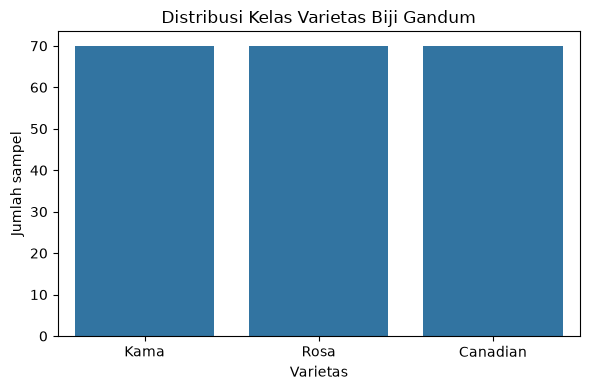

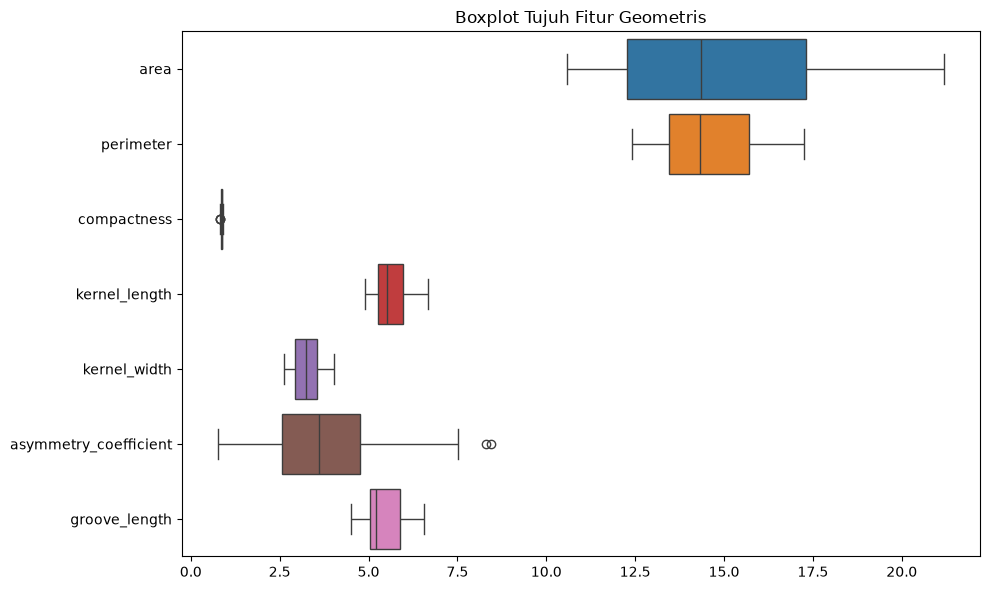

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y, order=LABEL_ORDER)
plt.title("Distribusi Kelas Varietas Biji Gandum")
plt.xlabel("Varietas")
plt.ylabel("Jumlah sampel")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=X, orient="h")
plt.title("Boxplot Tujuh Fitur Geometris")
plt.tight_layout()
plt.show()

## 5. Menetapkan model baseline
KNN menggunakan StandardScaler di dalam Pipeline agar scaler hanya dipelajari dari data training pada setiap fold. Decision Tree dan Gaussian Naive Bayes menggunakan fitur numerik asli.

In [6]:
models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5, weights="uniform", metric="minkowski", p=2)),
    ]),
    "Decision Tree": DecisionTreeClassifier(criterion="gini", max_depth=None, random_state=RANDOM_STATE),
    "Gaussian Naive Bayes": GaussianNB(var_smoothing=1e-9),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}
print("Model:", list(models.keys()))
print("Jumlah fold:", cv.get_n_splits(X, y))

Model: ['KNN', 'Decision Tree', 'Gaussian Naive Bayes']
Jumlah fold: 5


## 6. Evaluasi Stratified 5-Fold Cross-Validation
Tabel berikut menampilkan rata-rata dan simpangan baku dari lima fold. Macro average memberi bobot yang sama pada ketiga varietas.

In [7]:
hasil = []
for nama, model in models.items():
    skor = cross_validate(
        model, X, y,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1,
    )
    baris = {"Algoritma": nama}
    for metrik in scoring:
        nilai = skor[f"test_{metrik}"]
        baris[f"{metrik}_mean"] = nilai.mean()
        baris[f"{metrik}_std"] = nilai.std(ddof=1)
    hasil.append(baris)

hasil_df = pd.DataFrame(hasil).sort_values("f1_macro_mean", ascending=False)
display(hasil_df.style.format({c: "{:.4f}" for c in hasil_df.columns if c != "Algoritma"}))

,Algoritma,accuracy_mean,accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,f1_macro_mean,f1_macro_std
0,KNN,0.9238,0.0616,0.9270,0.0584,0.9238,0.0616,0.9228,0.0631
1,Decision Tree,0.8952,0.0548,0.9008,0.0554,0.8952,0.0548,0.8929,0.0578
2,Gaussian Naive Bayes,0.8905,0.0548,0.8992,0.0507,0.8905,0.0548,0.8888,0.0576


## 7. Confusion matrix dan laporan per kelas
Prediksi diperoleh menggunakan `cross_val_predict`, sehingga setiap sampel diprediksi oleh model yang tidak dilatih menggunakan sampel tersebut dalam fold terkait.


=== KNN ===
              precision    recall  f1-score   support

        Kama       0.90      0.87      0.88        70
        Rosa       0.96      0.96      0.96        70
    Canadian       0.92      0.94      0.93        70

    accuracy                           0.92       210
   macro avg       0.92      0.92      0.92       210
weighted avg       0.92      0.92      0.92       210



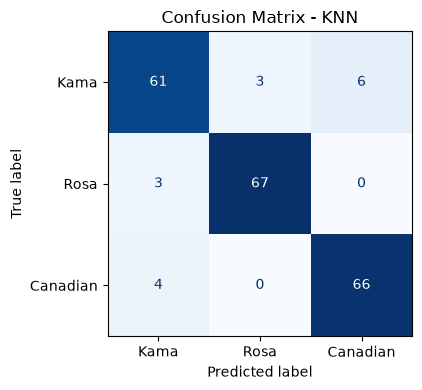


=== Decision Tree ===
              precision    recall  f1-score   support

        Kama       0.87      0.83      0.85        70
        Rosa       0.92      0.97      0.94        70
    Canadian       0.90      0.89      0.89        70

    accuracy                           0.90       210
   macro avg       0.89      0.90      0.89       210
weighted avg       0.89      0.90      0.89       210



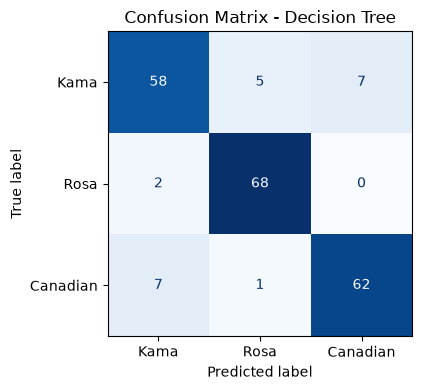


=== Gaussian Naive Bayes ===
              precision    recall  f1-score   support

        Kama       0.84      0.83      0.83        70
        Rosa       0.94      0.91      0.93        70
    Canadian       0.89      0.93      0.91        70

    accuracy                           0.89       210
   macro avg       0.89      0.89      0.89       210
weighted avg       0.89      0.89      0.89       210



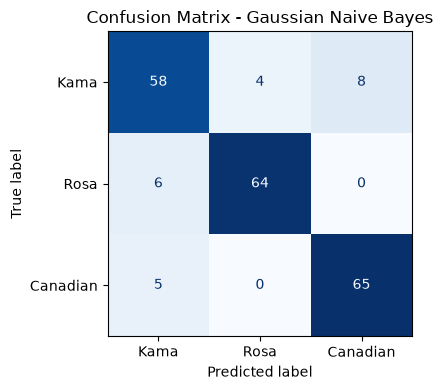

In [8]:
prediksi_oof = {}
for nama, model in models.items():
    y_pred = cross_val_predict(model, X, y, cv=cv, n_jobs=1)
    prediksi_oof[nama] = y_pred

    print(f"\n=== {nama} ===")
    print(classification_report(y, y_pred, labels=LABEL_ORDER, target_names=LABEL_ORDER, zero_division=0))

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y, y_pred,
        labels=LABEL_ORDER,
        display_labels=LABEL_ORDER,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"Confusion Matrix - {nama}")
    plt.tight_layout()
    plt.show()

## 8. Panduan membaca hasil

1. Gunakan **macro F1-score mean** sebagai metrik utama untuk mengurutkan model.
2. Periksa accuracy, macro precision, dan macro recall sebagai informasi pelengkap.
3. Simpangan baku menunjukkan variasi hasil antarfold; nilai lebih kecil berarti lebih konsisten pada pembagian data yang diuji.
4. Gunakan confusion matrix untuk melihat kelas yang paling sering tertukar.
5. Jangan menyimpulkan model siap digunakan di lapangan hanya dari hasil dataset UCI. Validasi eksternal dengan data baru tetap diperlukan.

**Catatan:** hasil tabel dan grafik merupakan keluaran aktual setelah notebook dijalankan. Salin hasilnya ke proposal/laporan hanya setelah memeriksa kembali versi kode, konfigurasi, dan sumber data.